In [1]:
from typing_extensions import TypedDict

class State(TypedDict):
    graph_info:str
    

In [15]:
def start_play(state:State):
    print("Start play node has been called")
    return {"graph_info":state["graph_info"]+ "I am planning to play"}

def cricket(state:State):
    print("Cricket node has been called")
    return {"graph_info":state["graph_info"]+ "Cricket"}   

def badmintain(state:State):
    print("Badmintain node has been called")
    return {"graph_info" :state["graph_info"]+ "Badmintain"}     
   

In [16]:
import random
from typing import Literal

def random_play(state:State)->Literal['cricket', 'badmintain']:  
    if random.random()>0.5:
        return "cricket"
    else:
        return "badmintain"    

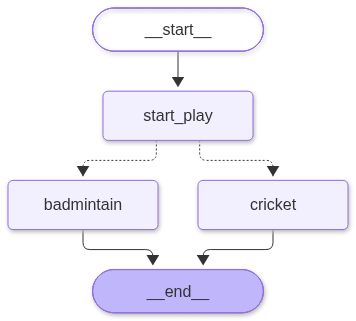

In [20]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

##Build the graph
graph=StateGraph(State)

##add all the node
graph.add_node("start_play", start_play)
graph.add_node("cricket", cricket)
graph.add_node("badmintain", badmintain)

##Schedule the flow of the graph
graph.add_edge(START, "start_play")
graph.add_conditional_edges("start_play", random_play)
graph.add_edge("cricket", END)
graph.add_edge("badmintain", END)

##compile the graph
graph_builder=graph.compile()

## view
display(Image(graph_builder.get_graph().draw_mermaid_png()))
